In [1]:
# %% Setup
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# %% Carica l'npz
model_dir = "/data/riccardop02/datasets/gso/ASICS_GEL1140V_WhiteRoyalSilver"  # <-- oggetto da vedere
npz = np.load(f"{model_dir}/embeddingDINO.npz")

feats = npz["features"]  # (n_views, n_patches, dim) es. (14, 256, 768)
n_views, n_patches, dim = feats.shape
grid = int(np.sqrt(n_patches))  # es. 256 -> 16x16 patch grid
print(feats.shape, "grid:", grid, "x", grid)

(30, 256, 768) grid: 16 x 16


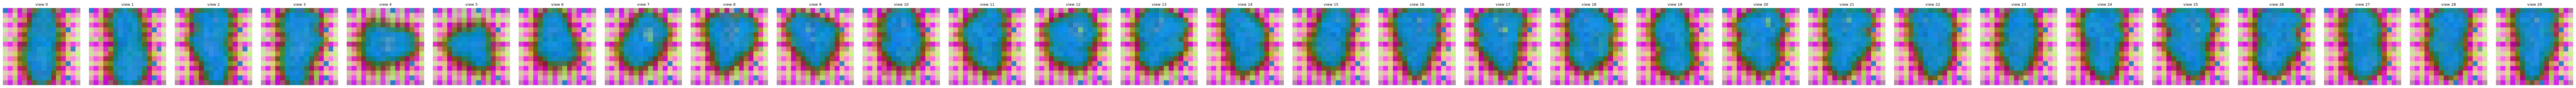

In [2]:
# %% PCA sui patch (fittata su tutte le viste insieme, cosi' i colori sono comparabili tra viste)
flat = feats.reshape(-1, dim)  # (n_views*n_patches, dim)

pca = PCA(n_components=3)
proj = pca.fit_transform(flat)  # (n_views*n_patches, 3)

# normalizza ogni componente in [0,1] per usarla come canale RGB
proj = (proj - proj.min(axis=0)) / (proj.max(axis=0) - proj.min(axis=0) + 1e-8)

proj = proj.reshape(n_views, grid, grid, 3)
# %% Visualizza
fig, axes = plt.subplots(1, n_views, figsize=(3 * n_views, 3))
if n_views == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    ax.imshow(proj[i])
    ax.set_title(f"view {i}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [3]:
# %% Setup extra per il render RGB vero
import os
os.environ["PYOPENGL_PLATFORM"] = "egl"
import sys
sys.path.append("/home/riccardop02/JEPA")  

import pyrender
from Script.cacheDINOView import render_views_systematic
from src.data.render_utils import build_pyrender_mesh

sys.path: ['/home/riccardop02/miniconda3/envs/poseJepa/lib/python311.zip', '/home/riccardop02/miniconda3/envs/poseJepa/lib/python3.11', '/home/riccardop02/miniconda3/envs/poseJepa/lib/python3.11/lib-dynload', '', '/home/riccardop02/miniconda3/envs/poseJepa/lib/python3.11/site-packages', '/home/riccardop02/JEPA', '/home/riccardop02/JEPA']


In [4]:
# %% Renderizza le view vere usando centroid/scale salvati nell'npz
centroid = npz["centroid"]
scale = float(npz["scale"])
image_size = 224

render_mesh = build_pyrender_mesh(model_dir)
renderer = pyrender.OffscreenRenderer(image_size, image_size)

rgb_images, _, _, _ = render_views_systematic(
    render_mesh, centroid, scale, image_size, n_views, renderer
)
renderer.delete()

rgb_images = [np.transpose(img, (1, 2, 0)) for img in rgb_images]  # (H,W,3) per plottare

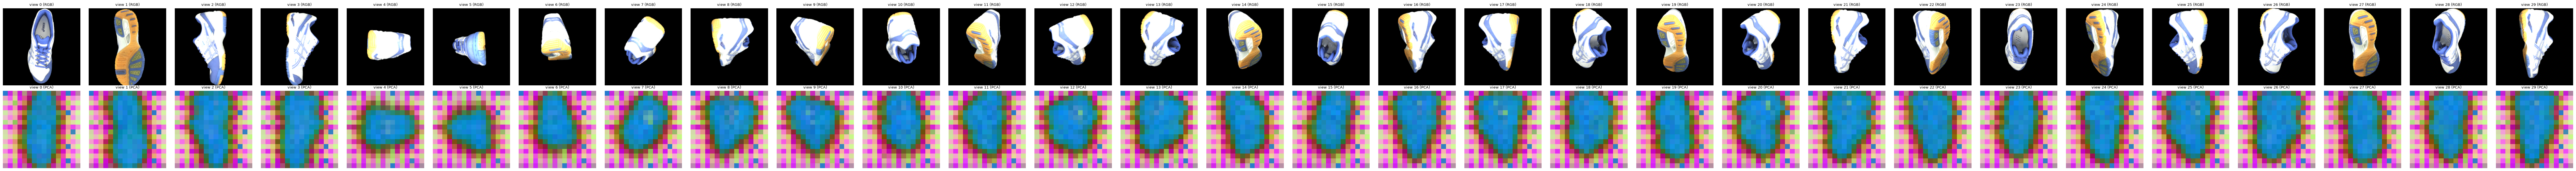

In [5]:
# %% Confronto affiancato: RGB vero (sopra) vs PCA dei patch (sotto)
fig, axes = plt.subplots(2, n_views, figsize=(3 * n_views, 6))

for i in range(n_views):
    axes[0, i].imshow(np.clip(rgb_images[i], 0, 1))
    axes[0, i].set_title(f"view {i} (RGB)", fontsize=9)
    axes[0, i].axis("off")

    axes[1, i].imshow(proj[i])
    axes[1, i].set_title(f"view {i} (PCA)", fontsize=9)
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()